# پاک‌سازی و پیش‌پردازش داده — نوت‌بوک همراه ارائهٔ دوم 🧹

**درس داده‌کاوی و یادگیری ماشین** | استاد درس: دکتر محمدرضا سلطان آقایی | ارائه‌دهنده: [نام و نام‌خانوادگی شما]

همراهِ اسلایدهای ۸ تا ۱۲ ارائهٔ دوم: مقادیر مفقود، هموارسازی با Binning، تبدیل و نرمال‌سازی (سه روش)، و اثر نرمال‌سازی بر KNN.

**ساختار:**
۱. مقادیر مفقود — شش راه‌حل در عمل
۲. هموارسازی دادهٔ نویزی با Binning (مثال ۹ قیمت)
۳. نرمال‌سازی: Min-Max، Z-Score و Decimal Scaling
۴. چرا نرمال‌سازی حیاتی است؟ اثرش را بر KNN ببینیم
۵. تمرین‌های پیشنهادی
---
### 🛠 راهنمای استفاده
- **ابزار:** همهٔ کدها در **Google Colab** اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: **Shift+Enter** یا منوی Runtime ▸ Run all).
- **یادگیری پایتون، از صفر:** [W3Schools — Python Tutorial](https://www.w3schools.com/python/default.asp) — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.
- **هر سلول:** توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.


## ۱) مقادیر مفقود — شش راه‌حل در عمل

یک جدول کوچک مشتری با چند مقدار مفقود (`NaN`) می‌سازیم و هر شش روش اسلاید درس را رویش آزمایش می‌کنیم:

In [1]:
# ساخت جدول نمونه با مقادیر مفقود (NaN) — شمارش با isna().sum()
import numpy as np
import pandas as pd

df = pd.DataFrame({
    'سن':      [22, 25, np.nan, 31, 35, 38, 42, np.nan],
    'درآمد':   [12, 14, 18, np.nan, 35, 40, 50, 38],
    'سابقه':   [1, 1, 2, 6, np.nan, 9, 12, 11],
    'پرداخت':  ['No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes'],
})
print('تعداد مقادیر مفقود در هر ستون:')
df.isna().sum()

تعداد مقادیر مفقود در هر ستون:


سن        2
درآمد     1
سابقه     1
پرداخت    0
dtype: int64

In [2]:
# روش ۱: نادیده گرفتن تاپل‌های ناقص
print(df.dropna().shape, '-> ساده اما اگر مقادیر مفقود زیاد باشند، دادهٔ آموزش را از دست می‌دهیم')

# روش ۲: پر کردن دستی (مناسب وقتی فقط چند مورد است و دانش دامنه داریم)
print('روش ۲: df.loc[2, "سن"] = 27  # پر کردن دستی با دانش دامنه')

# روش ۳: ثابت سراسری
m3 = df.fillna({'سن': -1})
print('روش ۳ (ثابت سراسری):', m3.loc[2, 'سن'])

# روش ۴: میانگین همان Attribute
m4 = df['سن'].fillna(df['سن'].mean())
print(f'روش ۴ (میانگین سن): {m4.iloc[2]:.2f}')

# روش ۵: میانگین همان کلاس (دقیق‌تر!) — میانگین سنِ گروه‌های پرداخت Yes/No
class_mean = df.groupby('پرداخت')['سن'].transform('mean')
m5 = df['سن'].fillna(class_mean)
print(f'روش ۵ (میانگین کلاس): گروه No -> {m5.iloc[2]:.2f}')

# روش ۶: محتمل‌ترین مقدار با یک مدل (اینجا: رگرسیون خطی ساده از روی درآمد)
from sklearn.linear_model import LinearRegression
ok = df.dropna(subset=['سن', 'درآمد'])
reg = LinearRegression().fit(ok[['درآمد']], ok['سن'])
pred = reg.predict(df.loc[df['سن'].isna(), ['درآمد']])
print(f'روش ۶ (پیش‌بینی با مدل): {pred.round(1)}')

(4, 4) -> ساده اما اگر مقادیر مفقود زیاد باشند، دادهٔ آموزش را از دست می‌دهیم
روش ۲: df.loc[2, "سن"] = 27  # پر کردن دستی با دانش دامنه
روش ۳ (ثابت سراسری): -1.0
روش ۴ (میانگین سن): 32.17
روش ۵ (میانگین کلاس): گروه No -> 23.50


روش ۶ (پیش‌بینی با مدل): [26.1 36.4]


## ۲) هموارسازی دادهٔ نویزی با Binning

مثال اسلاید ۹: ۹ قیمت مرتب‌شده را به **سه پیالهٔ هم‌عمق** تقسیم می‌کنیم و با دو روش هموار می‌کنیم:
- **میانگین پیاله**: هر مقدار → میانگین پیاله‌اش
- **مرز پیاله**: هر مقدار → نزدیک‌ترین مرز (کمینه/بیشینه) پیاله‌اش

In [3]:
# هموارسازی با Binning: سه پیالهٔ سه‌تایی؛ هر مقدار به میانگین یا مرزِ نزدیک‌تر پیاله می‌رود
prices = np.array([4, 8, 15, 21, 21, 24, 25, 28, 34], dtype=float)
bins = prices.reshape(3, 3)                     # سه پیالهٔ هم‌عمق

smooth_mean = np.repeat(bins.mean(axis=1), 3)    # میانگین پیاله
smooth_bound = np.array([[b[0] if abs(v-b[0]) <= abs(v-b[-1]) else b[-1]
                          for v in b] for b in bins]).ravel()

out = pd.DataFrame({
    'خام (مرتب‌شده)': prices,
    'پیاله': np.repeat(['Bin1', 'Bin2', 'Bin3'], 3),
    'هموار با میانگین': smooth_mean,
    'هموار با مرز': smooth_bound,
})
out

,خام (مرتب‌شده),پیاله,هموار با میانگین,هموار با مرز
0,4.0,Bin1,9.0,4.0
1,8.0,Bin1,9.0,4.0
2,15.0,Bin1,9.0,15.0
3,21.0,Bin2,22.0,21.0
4,21.0,Bin2,22.0,21.0
5,24.0,Bin2,22.0,24.0
6,25.0,Bin3,29.0,25.0
7,28.0,Bin3,29.0,25.0
8,34.0,Bin3,29.0,34.0


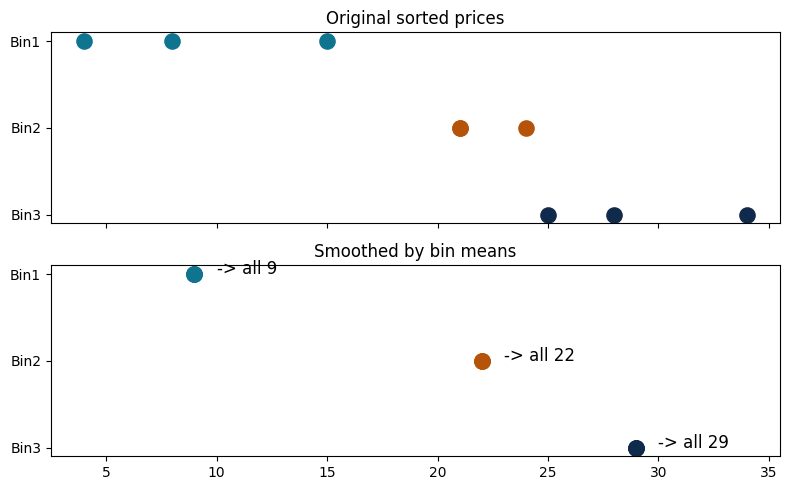

In [4]:
# مصورسازی قبل/بعدِ Binning — نقاط پرنوسان به میانگین پیاله هموار می‌شوند
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
colors = ['#0E7490', '#B45309', '#0F2A4A']
for i in range(3):
    axes[0].scatter(bins[i], np.full(3, 2-i), s=120, c=colors[i])
    axes[1].scatter(np.full(3, bins[i].mean()), np.full(3, 2-i), s=120, c=colors[i])
    axes[1].annotate(f'-> all {bins[i].mean():.0f}', (bins[i].mean()+1, 2-i), fontsize=12)
axes[0].set_yticks([2,1,0], ['Bin1','Bin2','Bin3']); axes[0].set_title('Original sorted prices')
axes[1].set_yticks([2,1,0], ['Bin1','Bin2','Bin3']); axes[1].set_title('Smoothed by bin means')
plt.tight_layout(); plt.show()

## ۳) نرمال‌سازی — سه روش منبع درس

### Min-Max — مثال جدول سن اسلاید ۱۱ (سن‌های ۲۰ تا ۳۲)

In [5]:
# Min-Max با دست: (x−min)/(max−min) برای ستون سن — همان فرمول اسلاید
ages = pd.Series([20, 23, 25, 29, 30, 32], name='سن')
minmax = (ages - ages.min()) / (ages.max() - ages.min())
pd.DataFrame({'سن': ages,
              'محاسبه': [f'({a}-{ages.min()})/({ages.max()}-{ages.min()})' for a in ages],
              'نرمال Min-Max': minmax.round(3)})

,سن,محاسبه,نرمال Min-Max
0,20,(20-20)/(32-20),0.000
1,23,(23-20)/(32-20),0.250
2,25,(25-20)/(32-20),0.417
3,29,(29-20)/(32-20),0.750
4,30,(30-20)/(32-20),0.833
5,32,(32-20)/(32-20),1.000


### Z-Score و Decimal Scaling

In [6]:
# Z-Score و Decimal Scaling — µ و σ از خودِ داده محاسبه می‌شود
mu, sd = ages.mean(), ages.std()
zscore = (ages - mu) / sd
decimal = ages / 100                      # j=2 (کوچک‌ترین توان ۱۰ که |مقدار|<۱ کند)
print(f'μ = {mu:.2f} , σ = {sd:.2f}')
pd.DataFrame({'سن': ages, 'Z-Score': zscore.round(3), 'Decimal (/100)': decimal})

μ = 26.50 , σ = 4.59


,سن,Z-Score,Decimal (/100)
0,20,-1.415,0.20
1,23,-0.762,0.23
2,25,-0.327,0.25
3,29,0.544,0.29
4,30,0.762,0.30
5,32,1.197,0.32


In [7]:
# با sklearn — MinMaxScaler و StandardScaler
from sklearn.preprocessing import MinMaxScaler, StandardScaler
X = np.array([[20], [23], [25], [29], [30], [32]])
print('MinMaxScaler:', MinMaxScaler().fit_transform(X).ravel().round(3))
print('StandardScaler:', StandardScaler().fit_transform(X).ravel().round(3))

MinMaxScaler: [0.    0.25  0.417 0.75  0.833 1.   ]
StandardScaler: [-1.55  -0.835 -0.358  0.596  0.835  1.312]


## ۴) چرا نرمال‌سازی حیاتی است؟ اثرش را بر KNN ببینیم

در ارائهٔ اول گفتیم KNN فاصله‌محور است. حالا با دادهٔ اقساط (همان جدول ۱۰ مشتری ارائهٔ اول) نشان می‌دهیم نرمال‌سازی چطور فاصله‌ها را **متعادل** می‌کند:

In [8]:
# اثر نرمال‌سازی بر KNN: فاصلهٔ خام در برابر فاصلهٔ بعد از Min-Max (درس اسلاید ۵)
cust = np.array([[22,12,1],[25,14,1],[27,18,2],[31,30,6],[35,35,8],
                 [38,40,9],[42,50,12],[45,38,11],[48,45,15],[55,60,20]], dtype=float)
paid = np.array(['No','No','No','Yes','Yes','Yes','Yes','Yes','Yes','Yes'])
new = np.array([33, 32, 5], dtype=float)                     # مشتری جدید (سن ۳۳، درآمد ۳۲، سابقه ۵)

d_raw = np.abs(cust - new).sum(axis=1)                        # فاصلهٔ منهتن خام
lo, hi = cust.min(axis=0), cust.max(axis=0)
d_norm = np.abs((cust-lo)/(hi-lo) - (new-lo)/(hi-lo)).sum(axis=1)   # بعد از Min-Max

res = pd.DataFrame({
    'مشتری': range(1, 11), 'پرداخت': paid,
    'فاصلهٔ خام': d_raw.round(1), 'فاصلهٔ نرمال': d_norm.round(3),
})
print('۴ همسایهٔ نزدیک (خام):', (d_raw.argsort()[:4]+1).tolist())
print('۴ همسایهٔ نزدیک (نرمال):', (d_norm.argsort()[:4]+1).tolist())
res

۴ همسایهٔ نزدیک (خام): [4, 5, 6, 3]
۴ همسایهٔ نزدیک (نرمال): [4, 5, 6, 3]


,مشتری,پرداخت,فاصلهٔ خام,فاصلهٔ نرمال
0,1,No,35.0,0.961
1,2,No,30.0,0.828
2,3,No,23.0,0.631
3,4,Yes,5.0,0.155
4,5,Yes,8.0,0.281
5,6,Yes,17.0,0.529
6,7,Yes,34.0,1.016
7,8,Yes,24.0,0.804
8,9,Yes,38.0,1.252
9,10,Yes,65.0,2.039


**نکته:** در این مثالِ خاص مجموع ۴ همسایهٔ نزدیک تغییر نکرد (مشتری‌های ۴، ۵، ۶، ۳) — اما دقت کنید **وزن نسبی** ویژگی‌ها عوض شد: در فاصلهٔ خام، «درآمد» (دامنهٔ ۴۸) تقریباً همهٔ فاصله را می‌ساخت و «سابقه» (دامنهٔ ۱۹) تقریباً نادیده بود؛ بعد از نرمال‌سازی هر سه ویژگی هم‌وزن شدند. با دادهٔ واقعی (که دامنه‌ها هزاران برابر هم فاصله دارند، مثل درآمد به تومان!) ترتیب همسایه‌ها به‌راحتی عوض می‌شود.

**میان‌بر عملی:** وقتی الگوریتم فاصله‌محور است (KNN، SVM، K-Means)، همیشه قبل از آموزش `MinMaxScaler` یا `StandardScaler` بزنید.

### ۴‌ب) همان مثال، با درآمد به «تومان» — حالا همسایه‌ها عوض می‌شوند

در مثال قبل دامنهٔ درآمد فقط ۱۲ تا ۶۰ بود و ۴ همسایهٔ نزدیک حفظ شد. اما در دنیای واقعی درآمد به تومان است (دامنه‌ای میلیون‌ها برابرِ سن). حالا ببینید فاصلهٔ خام چه می‌کند و Min-Max چه:

In [ ]:
# همان ۱۰ مشتری، ولی درآمد به میلیون تومان (مقیاس واقعی)
cust2 = cust.copy(); cust2[:, 1] *= 1_000_000      # درآمد: 12M تا 60M
new2  = new.copy();  new2[1]  *= 1_000_000         # مشتری جدید: درآمد 32M

d_raw2  = np.abs(cust2 - new2).sum(axis=1)                     # فاصلهٔ خام
lo2, hi2 = cust2.min(axis=0), cust2.max(axis=0)
d_norm2 = np.abs((cust2 - lo2)/(hi2 - lo2) - (new2 - lo2)/(hi2 - lo2)).sum(axis=1)

print('۴ همسایهٔ نزدیک (خام — درآمد به تومان):', (d_raw2.argsort()[:4] + 1).tolist())
print('۴ همسایهٔ نزدیک (بعد از Min-Max):      ', (d_norm2.argsort()[:4] + 1).tolist())

۴ همسایهٔ نزدیک (خام — درآمد به تومان): [4, 5, 8, 6]
۴ همسایهٔ نزدیک (بعد از Min-Max):      [4, 5, 6, 3]


**نتیجه:** با فاصلهٔ خام، عملاً فقط «پول» همسایگی را تعیین می‌کند — مشتریِ خوش‌سابقهٔ ۳ حذف و مشتریِ ۸ (که فقط چون درآمدش نزدیک بود وارد شد) جایش را می‌گیرد. بعد از Min-Max هر سه ویژگی هم‌وزن می‌شوند و همسایه‌های متعادل قبلی برمی‌گردند. **هر جا الگوریتم فاصله‌محور است (KNN، SVM، K-Means)، اول مقیاس‌دهی کنید.**

## ۵) جمع‌بندی و تمرین‌ها ✅

- مقادیر مفقود: از حذف ساده تا پر کردن با مدل — انتخاب به نسبت دادهٔ مفقود و اهمیت ویژگی بستگی دارد.
- Binning سه‌گانه (پیاله‌بندی، رگرسیون، خوشه‌بندی) برای **هموارسازی نویز**؛ نقاط خارج از خوشه‌ها در خوشه‌بندی همان outlierها هستند.
- سه روش نرمال‌سازی: Min-Max (دامنهٔ [۰،۱])، Z-Score (میانگین ۰، انحراف ۱)، Decimal (تقسیم بر توان ۱۰).

**تمرین‌ها:**
1. در جدول مشتریان، ستون درآمد را از «میلیون تومان» به «تومان» (×۱۰⁶) تبدیل کنید و فاصله‌های خام را دوباره حساب کنید — کدام ویژگی حالا فاصله را دیکته می‌کند؟
2. به‌جای میانگین پیاله، هموارسازی با **میانهٔ پیاله** را پیاده‌سازی کنید و نتیجه را مقایسه کنید.
3. با `StandardScaler` همان جدول را استاندارد کنید و تفاوت خروجی با Min-Max را ببینید.
4. (چالشی) روش ششم پر کردن مقادیر مفقود را با `KNeighborsRegressor` به‌جای رگرسیون خطی اجرا کنید.